In [1]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))


In [5]:
## Add PC1 and PC2
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

gbif_summary <- fread("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_all_CS_log10_notrim_na.csv")
head(gbif_summary)

h3_res3,count_all,count_native,count_sp_all,count_sp_native,rec_woody,rec_nonwoody,perc_woody,perc_nonwoody,mean_perc_na_all,⋯,X.X47..mean_native,X.X47..median_all,X.X47..median_native,X.X47..percent_change_mean,X.X47..percent_change_median,X.X47..n_na_all,X.X47..perc_na_all,X.X47..n_na_native,X.X47..perc_na_native,resolution
<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<int>,<dbl>,<chr>
83831efffffffff,150,84,73,39,99,32,66.00,21.33,15.19,⋯,0.322,0.352,0.354,0.00,-0.56,37,24.67,16,19.05,h3_res3
838218fffffffff,38,29,28,23,23,12,60.53,31.58,21.27,⋯,0.293,0.276,0.285,-6.83,-3.16,10,26.32,10,34.48,h3_res3
838233fffffffff,30,16,21,12,25,4,83.33,13.33,15.32,⋯,0.290,0.324,0.280,3.79,15.71,8,26.67,7,43.75,h3_res3
838230fffffffff,35,20,28,15,21,11,60.00,31.43,18.53,⋯,0.308,0.305,0.315,-1.30,-3.17,11,31.43,8,40.00,h3_res3
83be4dfffffffff,30491,29890,541,400,24063,4309,78.92,14.13,22.81,⋯,0.496,0.497,0.514,-1.21,-3.31,7924,25.99,7837,26.22,h3_res3
835f12fffffffff,10986,9472,1087,945,7082,3314,64.46,30.17,21.39,⋯,0.303,0.305,0.307,-0.33,-0.65,2374,21.61,2095,22.12,h3_res3


In [6]:
dim(gbif_summary)

[1] 9902  382

In [7]:
summary(gbif_summary$X.X47..mean_all)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
 0.0700  0.2550  0.2810  0.2896  0.3140  0.6560     153 

In [8]:
# are there rows where gbif_summary$count_native == 0
nrow(gbif_summary[gbif_summary$count_native == 0, ])

[1] 150

In [9]:
nrow(gbif_summary[gbif_summary$count_native < 100, ])

[1] 5319

In [10]:
# filter out rows where count_native is less than 100
#gbif_summary <- gbif_summary[count_native >= 100]


# filter out rows where count_native is 0
gbif_summary <- gbif_summary[count_native > 0]
dim(gbif_summary)
dim(gbif_summary)

[1] 9752  382

[1] 9752  382

In [11]:
head(gbif_summary)

h3_res3,count_all,count_native,count_sp_all,count_sp_native,rec_woody,rec_nonwoody,perc_woody,perc_nonwoody,mean_perc_na_all,⋯,X.X47..mean_native,X.X47..median_all,X.X47..median_native,X.X47..percent_change_mean,X.X47..percent_change_median,X.X47..n_na_all,X.X47..perc_na_all,X.X47..n_na_native,X.X47..perc_na_native,resolution
<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<int>,<dbl>,<chr>
83831efffffffff,150,84,73,39,99,32,66.00,21.33,15.19,⋯,0.322,0.352,0.354,0.00,-0.56,37,24.67,16,19.05,h3_res3
838218fffffffff,38,29,28,23,23,12,60.53,31.58,21.27,⋯,0.293,0.276,0.285,-6.83,-3.16,10,26.32,10,34.48,h3_res3
838233fffffffff,30,16,21,12,25,4,83.33,13.33,15.32,⋯,0.290,0.324,0.280,3.79,15.71,8,26.67,7,43.75,h3_res3
838230fffffffff,35,20,28,15,21,11,60.00,31.43,18.53,⋯,0.308,0.305,0.315,-1.30,-3.17,11,31.43,8,40.00,h3_res3
83be4dfffffffff,30491,29890,541,400,24063,4309,78.92,14.13,22.81,⋯,0.496,0.497,0.514,-1.21,-3.31,7924,25.99,7837,26.22,h3_res3
835f12fffffffff,10986,9472,1087,945,7082,3314,64.46,30.17,21.39,⋯,0.303,0.305,0.307,-0.33,-0.65,2374,21.61,2095,22.12,h3_res3


In [12]:
# Select columns whose names end with "_mean_all" or "_mean_native"
trait_matrix <- gbif_summary[, grep("mean_(all|native)$", names(gbif_summary)), with = FALSE]

head(trait_matrix)

X.X3117..mean_all,X.X3117..mean_native,X.X14..mean_all,X.X14..mean_native,X.X50..mean_all,X.X50..mean_native,X.X146..mean_all,X.X146..mean_native,X.X3120..mean_all,X.X3120..mean_native,⋯,X.X138..mean_all,X.X138..mean_native,X.X1080..mean_all,X.X1080..mean_native,X.X78..mean_all,X.X78..mean_native,X.X4..mean_all,X.X4..mean_native,X.X47..mean_all,X.X47..mean_native
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
17.379,16.271,25.460,23.225,1.662,1.561,21.233,22.426,4.147,4.568,⋯,2.187,2.272,2.984,3.115,1.390,1.213,0.444,0.420,0.322,0.322
18.735,18.166,24.025,23.001,1.584,1.612,22.095,23.548,3.967,3.840,⋯,2.013,1.935,3.227,3.160,1.426,1.439,0.505,0.533,0.273,0.293
16.060,14.784,24.569,24.338,1.759,1.794,20.941,22.751,3.230,3.367,⋯,1.703,1.315,3.139,3.004,2.137,2.012,0.543,0.576,0.301,0.290
17.288,15.522,25.251,22.007,1.751,1.717,21.007,24.100,3.816,3.869,⋯,2.139,2.103,3.015,2.859,1.600,0.933,0.447,0.444,0.304,0.308
7.119,6.868,13.338,13.089,2.526,2.546,44.473,44.958,2.041,1.973,⋯,2.418,2.411,3.263,3.255,-0.430,-0.462,0.661,0.666,0.490,0.496
17.637,17.420,22.000,21.563,1.485,1.471,24.232,24.744,3.962,3.904,⋯,2.182,2.160,3.224,3.227,1.438,1.455,0.502,0.516,0.302,0.303


In [13]:
length(names(trait_matrix))

[1] 74

In [14]:
dim(trait_matrix)

[1] 9752   74


### Imputation of missing data



In [15]:
na_summary <- data.frame(
    column = names(trait_matrix),
    na_count = colSums(is.na(trait_matrix)),
    na_percentage = colMeans(is.na(trait_matrix)) * 100
)

na_summary

,column,na_count,na_percentage
,<chr>,<dbl>,<dbl>
X.X3117..mean_all,X.X3117..mean_all,128,1.3125513
X.X3117..mean_native,X.X3117..mean_native,152,1.5586546
X.X14..mean_all,X.X14..mean_all,127,1.3022970
X.X14..mean_native,X.X14..mean_native,155,1.5894176
X.X50..mean_all,X.X50..mean_all,122,1.2510254
X.X50..mean_native,X.X50..mean_native,158,1.6201805
X.X146..mean_all,X.X146..mean_all,137,1.4048400
X.X146..mean_native,X.X146..mean_native,166,1.7022149
X.X3120..mean_all,X.X3120..mean_all,159,1.6304348


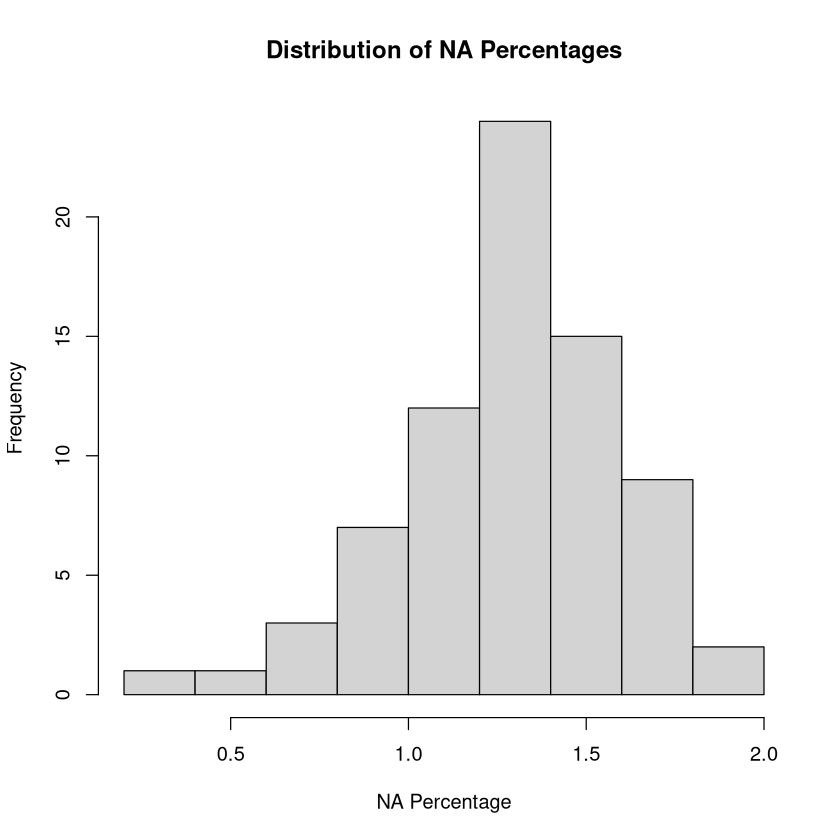

In [16]:
# plot historgramm na_percentage
hist(na_summary$na_percentage, main="Distribution of NA Percentages", xlab="NA Percentage", ylab="Frequency")

In [17]:

# Calculate total missingness
total_missingness <- sum(is.na(trait_matrix)) / prod(dim(trait_matrix))
print(total_missingness)



[1] 0.01290518


Get info on degreee of missingness: Missingness is quite low. Impute missing trait means using missForest package 


In [18]:
library(missForest)

# Select the 37 native-only trait columns
native_cols <- grep("\\.mean_native$", names(trait_matrix), value = TRUE)

# Select the 37 native + introduced trait columns
all_cols <- grep("\\.mean_all$", names(trait_matrix), value = TRUE)


# -------------------------
# Native-only
# -------------------------

native_traits <- as.data.frame(trait_matrix[, ..native_cols])

set.seed(123)

native_imp <- missForest(
  native_traits,
  maxiter = 10,
  ntree = 100
)

trait_matrix[, (native_cols) := native_imp$ximp]


# -------------------------
# Native + introduced
# -------------------------

all_traits <- as.data.frame(trait_matrix[, ..all_cols])

set.seed(123)

all_imp <- missForest(
  all_traits,
  maxiter = 10,
  ntree = 100
)

trait_matrix[, (all_cols) := all_imp$ximp]

In [19]:
head(all_imp$ximp)

,X.X3117..mean_all,X.X14..mean_all,X.X50..mean_all,X.X146..mean_all,X.X3120..mean_all,X.X224..mean_all,X.X297..mean_all,X.X21..mean_all,X.X13..mean_all,X.X15..mean_all,⋯,X.X237..mean_all,X.X614..mean_all,X.X351..mean_all,X.X6..mean_all,X.X95..mean_all,X.X138..mean_all,X.X1080..mean_all,X.X78..mean_all,X.X4..mean_all,X.X47..mean_all
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,17.379,25.460,1.662,21.233,4.147,0.411,0.865,-1.082,448.865,1.835,⋯,0.792,3.229,0.096,-0.056,85.078,2.187,2.984,1.390,0.444,0.322
2,18.735,24.025,1.584,22.095,3.967,0.384,0.998,-1.320,443.451,1.666,⋯,0.746,3.370,0.060,0.166,87.139,2.013,3.227,1.426,0.505,0.273
3,16.060,24.569,1.759,20.941,3.230,0.444,1.058,-1.143,449.407,1.804,⋯,0.854,3.342,0.078,0.155,89.118,1.703,3.139,2.137,0.543,0.301
4,17.288,25.251,1.751,21.007,3.816,0.470,0.876,-1.030,448.350,2.006,⋯,0.834,3.237,0.065,0.069,88.969,2.139,3.015,1.600,0.447,0.304
5,7.119,13.338,2.526,44.473,2.041,0.342,1.078,-1.288,480.149,0.734,⋯,0.536,3.283,0.032,0.137,87.296,2.418,3.263,-0.430,0.661,0.490
6,17.637,22.000,1.485,24.232,3.962,0.412,0.974,-1.303,455.843,1.391,⋯,0.703,3.384,0.029,-0.062,86.777,2.182,3.224,1.438,0.502,0.302


In [20]:
head(native_imp$ximp)

,X.X3117..mean_native,X.X14..mean_native,X.X50..mean_native,X.X146..mean_native,X.X3120..mean_native,X.X224..mean_native,X.X297..mean_native,X.X21..mean_native,X.X13..mean_native,X.X15..mean_native,⋯,X.X237..mean_native,X.X614..mean_native,X.X351..mean_native,X.X6..mean_native,X.X95..mean_native,X.X138..mean_native,X.X1080..mean_native,X.X78..mean_native,X.X4..mean_native,X.X47..mean_native
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,16.271,23.225,1.561,22.426,4.568,0.519,0.792,-1.084,443.273,1.972,⋯,0.717,3.231,0.107,-0.135,85.966,2.272,3.115,1.213,0.420,0.322
2,18.166,23.001,1.612,23.548,3.840,0.348,0.976,-1.080,446.626,1.583,⋯,0.807,3.320,0.064,0.225,85.014,1.935,3.160,1.439,0.533,0.293
3,14.784,24.338,1.794,22.751,3.367,0.393,1.072,-0.874,458.957,1.254,⋯,1.054,3.322,0.051,0.267,85.728,1.315,3.004,2.012,0.576,0.290
4,15.522,22.007,1.717,24.100,3.869,0.455,0.801,-0.835,446.835,1.988,⋯,0.870,3.126,0.097,0.162,87.713,2.103,2.859,0.933,0.444,0.308
5,6.868,13.089,2.546,44.958,1.973,0.337,1.081,-1.276,481.029,0.710,⋯,0.538,3.274,0.032,0.152,87.231,2.411,3.255,-0.462,0.666,0.496
6,17.420,21.563,1.471,24.744,3.904,0.401,0.972,-1.298,456.788,1.336,⋯,0.706,3.378,0.030,-0.049,86.423,2.160,3.227,1.455,0.516,0.303


In [21]:
# remove "..mean_all" from column names
names(all_imp$ximp) <- gsub("\\..mean_all$", "", names(all_imp$ximp))
names(native_imp$ximp) <- gsub("\\..mean_native$", "", names(native_imp$ximp))

In [22]:
head(gbif_summary)

h3_res3,count_all,count_native,count_sp_all,count_sp_native,rec_woody,rec_nonwoody,perc_woody,perc_nonwoody,mean_perc_na_all,⋯,X.X47..mean_native,X.X47..median_all,X.X47..median_native,X.X47..percent_change_mean,X.X47..percent_change_median,X.X47..n_na_all,X.X47..perc_na_all,X.X47..n_na_native,X.X47..perc_na_native,resolution
<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<int>,<dbl>,<chr>
83831efffffffff,150,84,73,39,99,32,66.00,21.33,15.19,⋯,0.322,0.352,0.354,0.00,-0.56,37,24.67,16,19.05,h3_res3
838218fffffffff,38,29,28,23,23,12,60.53,31.58,21.27,⋯,0.293,0.276,0.285,-6.83,-3.16,10,26.32,10,34.48,h3_res3
838233fffffffff,30,16,21,12,25,4,83.33,13.33,15.32,⋯,0.290,0.324,0.280,3.79,15.71,8,26.67,7,43.75,h3_res3
838230fffffffff,35,20,28,15,21,11,60.00,31.43,18.53,⋯,0.308,0.305,0.315,-1.30,-3.17,11,31.43,8,40.00,h3_res3
83be4dfffffffff,30491,29890,541,400,24063,4309,78.92,14.13,22.81,⋯,0.496,0.497,0.514,-1.21,-3.31,7924,25.99,7837,26.22,h3_res3
835f12fffffffff,10986,9472,1087,945,7082,3314,64.46,30.17,21.39,⋯,0.303,0.305,0.307,-0.33,-0.65,2374,21.61,2095,22.12,h3_res3


In [23]:
all_imp_df <- cbind(gbif_summary[, .(h3_res3, count_all, count_native, count_sp_all, count_sp_native, mean_perc_na_all)], all_imp$ximp)
native_imp_df <- cbind(gbif_summary[, .(h3_res3, count_all, count_native, count_sp_all, count_sp_native,mean_perc_na_native)], native_imp$ximp)


In [24]:
head(all_imp_df)
head(native_imp_df)

h3_res3,count_all,count_native,count_sp_all,count_sp_native,mean_perc_na_all,X.X3117,X.X14,X.X50,X.X146,⋯,X.X237,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47
<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83831efffffffff,150,84,73,39,15.19,17.379,25.460,1.662,21.233,⋯,0.792,3.229,0.096,-0.056,85.078,2.187,2.984,1.390,0.444,0.322
838218fffffffff,38,29,28,23,21.27,18.735,24.025,1.584,22.095,⋯,0.746,3.370,0.060,0.166,87.139,2.013,3.227,1.426,0.505,0.273
838233fffffffff,30,16,21,12,15.32,16.060,24.569,1.759,20.941,⋯,0.854,3.342,0.078,0.155,89.118,1.703,3.139,2.137,0.543,0.301
838230fffffffff,35,20,28,15,18.53,17.288,25.251,1.751,21.007,⋯,0.834,3.237,0.065,0.069,88.969,2.139,3.015,1.600,0.447,0.304
83be4dfffffffff,30491,29890,541,400,22.81,7.119,13.338,2.526,44.473,⋯,0.536,3.283,0.032,0.137,87.296,2.418,3.263,-0.430,0.661,0.490
835f12fffffffff,10986,9472,1087,945,21.39,17.637,22.000,1.485,24.232,⋯,0.703,3.384,0.029,-0.062,86.777,2.182,3.224,1.438,0.502,0.302


h3_res3,count_all,count_native,count_sp_all,count_sp_native,mean_perc_na_native,X.X3117,X.X14,X.X50,X.X146,⋯,X.X237,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47
<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83831efffffffff,150,84,73,39,14.12,16.271,23.225,1.561,22.426,⋯,0.717,3.231,0.107,-0.135,85.966,2.272,3.115,1.213,0.420,0.322
838218fffffffff,38,29,28,23,23.58,18.166,23.001,1.612,23.548,⋯,0.807,3.320,0.064,0.225,85.014,1.935,3.160,1.439,0.533,0.293
838233fffffffff,30,16,21,12,23.82,14.784,24.338,1.794,22.751,⋯,1.054,3.322,0.051,0.267,85.728,1.315,3.004,2.012,0.576,0.290
838230fffffffff,35,20,28,15,20.14,15.522,22.007,1.717,24.100,⋯,0.870,3.126,0.097,0.162,87.713,2.103,2.859,0.933,0.444,0.308
83be4dfffffffff,30491,29890,541,400,23.01,6.868,13.089,2.546,44.958,⋯,0.538,3.274,0.032,0.152,87.231,2.411,3.255,-0.462,0.666,0.496
835f12fffffffff,10986,9472,1087,945,22.04,17.420,21.563,1.471,24.744,⋯,0.706,3.378,0.030,-0.049,86.423,2.160,3.227,1.455,0.516,0.303


In [25]:
# save the imputed data frames to CSV files
fwrite(all_imp_df, "/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_CS_log10_notrim_imputed_all.csv")
fwrite(native_imp_df, "/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_CS_log10_notrim_imputed_native.csv")  

## Prepare data frmae

In [26]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

In [27]:
# read 
all_imp_df <- fread("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_CS_log10_notrim_imputed_all.csv")
native_imp_df <- fread("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_CS_log10_notrim_imputed_native.csv")

In [28]:
head(all_imp_df)

h3_res3,count_all,count_native,count_sp_all,count_sp_native,mean_perc_na_all,X.X3117,X.X14,X.X50,X.X146,⋯,X.X237,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47
<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83831efffffffff,150,84,73,39,15.19,17.379,25.460,1.662,21.233,⋯,0.792,3.229,0.096,-0.056,85.078,2.187,2.984,1.390,0.444,0.322
838218fffffffff,38,29,28,23,21.27,18.735,24.025,1.584,22.095,⋯,0.746,3.370,0.060,0.166,87.139,2.013,3.227,1.426,0.505,0.273
838233fffffffff,30,16,21,12,15.32,16.060,24.569,1.759,20.941,⋯,0.854,3.342,0.078,0.155,89.118,1.703,3.139,2.137,0.543,0.301
838230fffffffff,35,20,28,15,18.53,17.288,25.251,1.751,21.007,⋯,0.834,3.237,0.065,0.069,88.969,2.139,3.015,1.600,0.447,0.304
83be4dfffffffff,30491,29890,541,400,22.81,7.119,13.338,2.526,44.473,⋯,0.536,3.283,0.032,0.137,87.296,2.418,3.263,-0.430,0.661,0.490
835f12fffffffff,10986,9472,1087,945,21.39,17.637,22.000,1.485,24.232,⋯,0.703,3.384,0.029,-0.062,86.777,2.182,3.224,1.438,0.502,0.302


In [29]:
# remove columns count_all, count_native, count_sp_all, count_sp_native from both data frames
all_imp_df[, c("count_native", "count_sp_native") := NULL]
native_imp_df[, c("count_all", "count_sp_all") := NULL]

In [30]:
# rename count_native to count and count_sp_native to count_sp in native_imp_df
setnames(native_imp_df, old = c("count_native", "count_sp_native", "mean_perc_na_native"), new = c("count", "count_sp", "mean_perc_na"))

setnames(all_imp_df, old = c("count_all", "count_sp_all","mean_perc_na_all"), new = c("count", "count_sp", "mean_perc_na"))


In [31]:
# add column "group" to both data frames
all_imp_df[, group := "all"]
native_imp_df[, group := "native"]

In [32]:
head(native_imp_df)

h3_res3,count,count_sp,mean_perc_na,X.X3117,X.X14,X.X50,X.X146,X.X3120,X.X224,⋯,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47,group
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
83831efffffffff,84,39,14.12,16.271,23.225,1.561,22.426,4.568,0.519,⋯,3.231,0.107,-0.135,85.966,2.272,3.115,1.213,0.420,0.322,native
838218fffffffff,29,23,23.58,18.166,23.001,1.612,23.548,3.840,0.348,⋯,3.320,0.064,0.225,85.014,1.935,3.160,1.439,0.533,0.293,native
838233fffffffff,16,12,23.82,14.784,24.338,1.794,22.751,3.367,0.393,⋯,3.322,0.051,0.267,85.728,1.315,3.004,2.012,0.576,0.290,native
838230fffffffff,20,15,20.14,15.522,22.007,1.717,24.100,3.869,0.455,⋯,3.126,0.097,0.162,87.713,2.103,2.859,0.933,0.444,0.308,native
83be4dfffffffff,29890,400,23.01,6.868,13.089,2.546,44.958,1.973,0.337,⋯,3.274,0.032,0.152,87.231,2.411,3.255,-0.462,0.666,0.496,native
835f12fffffffff,9472,945,22.04,17.420,21.563,1.471,24.744,3.904,0.401,⋯,3.378,0.030,-0.049,86.423,2.160,3.227,1.455,0.516,0.303,native


In [33]:
#ROWBIND    
summary_df <- rbind(all_imp_df, native_imp_df)
# sort summary_df by h3_res3
summary_df <- summary_df[order(h3_res3)]
head(summary_df)

h3_res3,count,count_sp,mean_perc_na,X.X3117,X.X14,X.X50,X.X146,X.X3120,X.X224,⋯,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47,group
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
83001afffffffff,10,4,5.68,21.336,22.08000,1.108,21.36900,9.488,0.401,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152,all
83001afffffffff,10,4,5.68,21.336,22.08000,1.108,21.36900,9.488,0.401,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152,native
83001cfffffffff,1,1,16.22,15.259,19.08552,1.235,27.46942,8.495,0.447,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3166111,0.175,all
83001cfffffffff,1,1,16.22,15.259,18.59292,1.235,27.31443,8.495,0.447,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3291221,0.175,native
83001efffffffff,4,3,3.38,16.946,20.49600,1.295,23.68400,6.786,0.606,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211,all
83001efffffffff,4,3,3.38,16.946,20.49600,1.295,23.68400,6.786,0.606,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211,native


In [34]:
dim(summary_df)

[1] 19504    42

In [35]:
fwrite(summary_df, "/net/scratch/swolf/GBIF/gbif_CS_glonaf_wcvp_res3_try6_mean_log10_notrim_misstree.csv")


## Calculate PCA

In [36]:
gbif_imputed <- fread("/net/scratch/swolf/GBIF/gbif_CS_glonaf_wcvp_res3_try6_mean_log10_notrim_misstree.csv")


Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




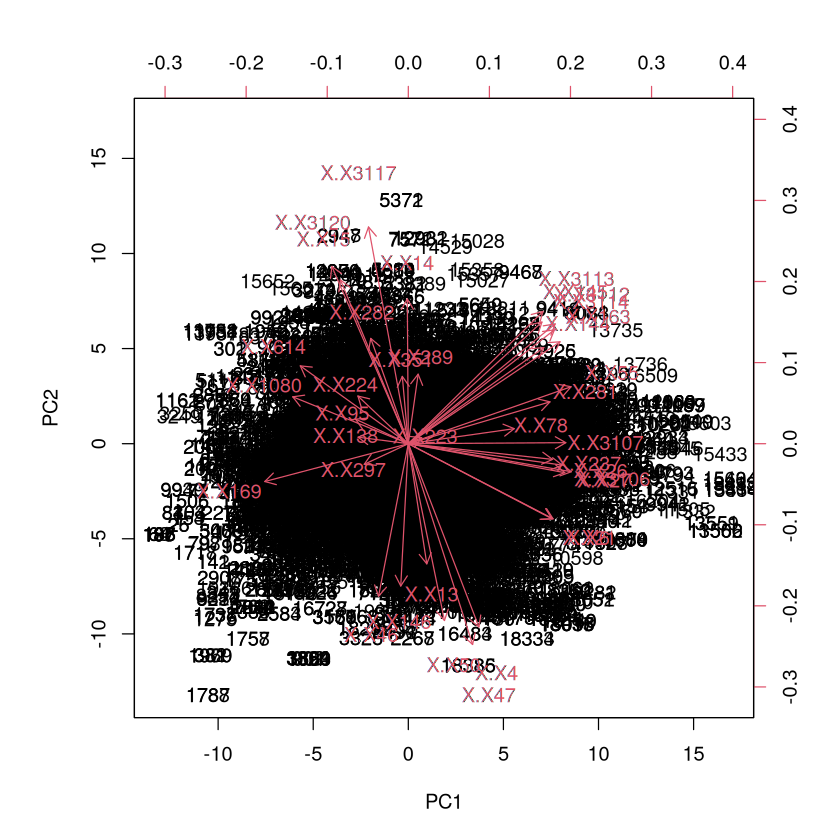

In [37]:
# Load other packages
library(ggplot2)
library(tidyr)
# Load dplyr last
library(dplyr)


# Perform PCA on the filtered and imputed mean trait data
pca_result <- prcomp(gbif_imputed %>% dplyr::select(starts_with("X")), center = TRUE, scale. = TRUE)
biplot(pca_result, scale = 0)


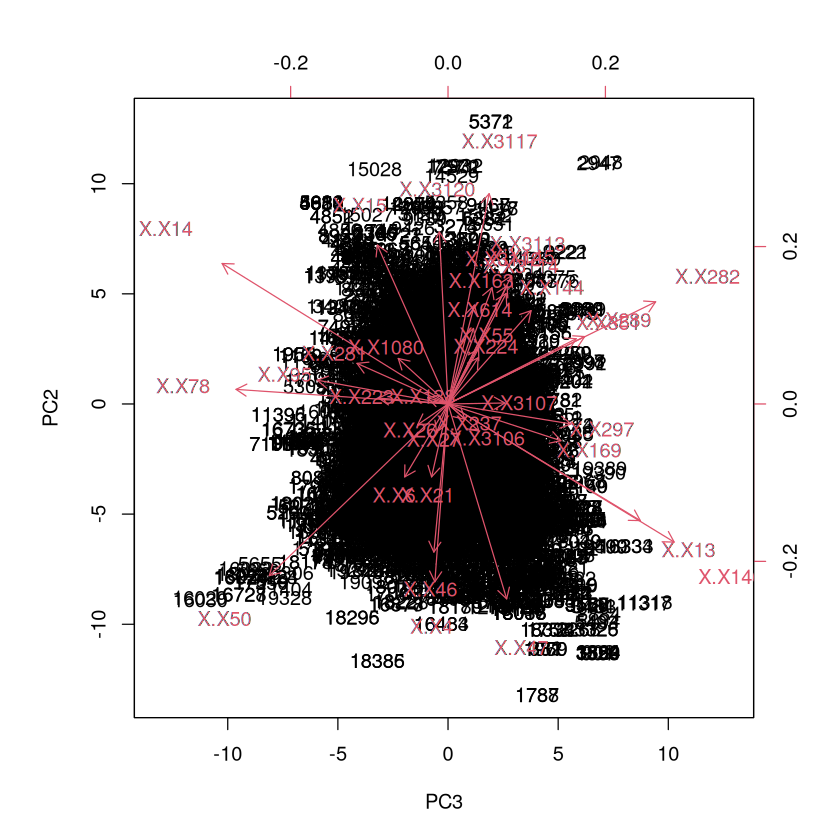

In [38]:
biplot(pca_result, choices = c(3, 2), scale = 0)


In [ ]:
#pca_result$rotation[, "PC3"] <- -pca_result$rotation[, "PC3"]
#pca_result$x[, "PC3"] <- -pca_result$x[, "PC3"]

### Hierarchical clustering of traits for each axis

In [39]:
loadings <- pca_result$rotation   # traits × PCs


In [40]:
contrib <- sweep(loadings^2, 2, colSums(loadings^2), FUN = "/") * 100
head(contrib)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,⋯,PC28,PC29,PC30,PC31,PC32,PC33,PC34,PC35,PC36,PC37
X.X3117,0.3766243385,11.1591681,0.4265677,0.6894520,1.1642937,0.08957873,0.113135521,0.05721160,1.79105722,0.7532779446,⋯,8.384389958,0.373034672,0.68297024,0.20760724,0.002770444,1.872903212,0.017590226,0.368091838,0.5390042973,0.0156402247
X.X14,0.0002425063,4.9783968,12.8741308,1.3175757,3.4596866,1.32891636,0.060419989,2.20056896,1.76327908,0.0155716866,⋯,2.838911037,2.653952414,0.03172318,0.50491880,0.145186121,0.002467323,0.026539671,0.001214524,0.0019240063,0.0004262674
X.X50,0.3106486143,7.4309252,8.0605670,1.0050364,0.2348901,0.04392781,0.009797596,1.86901457,0.89712426,0.4388410233,⋯,5.402124637,0.242155692,0.81619040,1.09443698,0.014159950,0.089955279,0.014499448,0.060005959,0.3444005028,0.0004269398
X.X146,0.0135769077,4.8121616,12.9003768,0.6875361,6.3963445,1.01646689,0.009373337,0.79453257,0.16442744,0.0003443635,⋯,0.007349388,3.097161894,0.50388514,0.01420761,1.767317948,0.086743307,0.221261678,0.012036169,0.2323525731,0.0064429137
X.X3120,1.3880611464,7.4642254,0.0189746,0.7331395,0.3976803,0.14039938,0.057352507,0.07637016,0.02293123,2.9441922382,⋯,2.087348003,1.145121901,0.12185703,0.28542005,1.919570509,0.741290657,0.009188594,0.001088616,0.0188581972,0.1024772694
X.X224,0.6035685642,0.5393882,0.2291561,18.5611819,2.0696248,9.22867084,6.688286843,5.00641815,1.40645469,8.2293627926,⋯,2.585506113,0.006234542,0.76663192,1.08445461,2.474835301,0.475740190,0.070485655,0.001476095,0.0001702931,0.0074820304


In [41]:
# read ~/Func_Neo_Phytes/Data/trait_info.csv
trait_info <- fread("/net/home/swolf/Func_Neo_Phytes/Data/trait_info.csv") 
# remove last character form each string in column "TraitID_TRY6"
trait_info$TraitID_TRY6 <- substr(trait_info$TraitID_TRY6, 1, nchar(trait_info$TraitID_TRY6) - 1)
head(trait_info)

TraitID,TraitID_TRY6,TraitName,ShortName,sPlotOpenName,UnitName
<int>,<chr>,<chr>,<chr>,<chr>,<chr>
4,X.X4,"Stem specific density (SSD, stem dry mass per stem fresh volume) or wood density",SSD,SSD,g/cm3
6,X.X6,Root rooting depth,Rooting depth,,m
13,X.X13,Leaf carbon (C) content per leaf dry mass,Leaf C,Leaf.C,mg/g
14,X.X14,Leaf nitrogen (N) content per leaf dry mass,Leaf N,Leaf.N.per.mass,mg/g
15,X.X15,Leaf phosphorus (P) content per leaf dry mass,Leaf P,Leaf.P,mg/g
21,X.X21,Stem diameter,Stem diameter,,m


In [42]:
# Set row names of contrib to "ShortName" from trait_info
rownames(contrib) <- trait_info$ShortName[match(rownames(contrib), trait_info$TraitID_TRY6)]
head(contrib)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,⋯,PC28,PC29,PC30,PC31,PC32,PC33,PC34,PC35,PC36,PC37
SLA petiole in- or excluded,0.3766243385,11.1591681,0.4265677,0.6894520,1.1642937,0.08957873,0.113135521,0.05721160,1.79105722,0.7532779446,⋯,8.384389958,0.373034672,0.68297024,0.20760724,0.002770444,1.872903212,0.017590226,0.368091838,0.5390042973,0.0156402247
Leaf N,0.0002425063,4.9783968,12.8741308,1.3175757,3.4596866,1.32891636,0.060419989,2.20056896,1.76327908,0.0155716866,⋯,2.838911037,2.653952414,0.03172318,0.50491880,0.145186121,0.002467323,0.026539671,0.001214524,0.0019240063,0.0004262674
Leaf N per area,0.3106486143,7.4309252,8.0605670,1.0050364,0.2348901,0.04392781,0.009797596,1.86901457,0.89712426,0.4388410233,⋯,5.402124637,0.242155692,0.81619040,1.09443698,0.014159950,0.089955279,0.014499448,0.060005959,0.3444005028,0.0004269398
Leaf C/N ratio,0.0135769077,4.8121616,12.9003768,0.6875361,6.3963445,1.01646689,0.009373337,0.79453257,0.16442744,0.0003443635,⋯,0.007349388,3.097161894,0.50388514,0.01420761,1.767317948,0.086743307,0.221261678,0.012036169,0.2323525731,0.0064429137
Leaf water content not saturated,1.3880611464,7.4642254,0.0189746,0.7331395,0.3976803,0.14039938,0.057352507,0.07637016,0.02293123,2.9441922382,⋯,2.087348003,1.145121901,0.12185703,0.28542005,1.919570509,0.741290657,0.009188594,0.001088616,0.0188581972,0.1024772694
Chromosome cDNA content,0.6035685642,0.5393882,0.2291561,18.5611819,2.0696248,9.22867084,6.688286843,5.00641815,1.40645469,8.2293627926,⋯,2.585506113,0.006234542,0.76663192,1.08445461,2.474835301,0.475740190,0.070485655,0.001476095,0.0001702931,0.0074820304


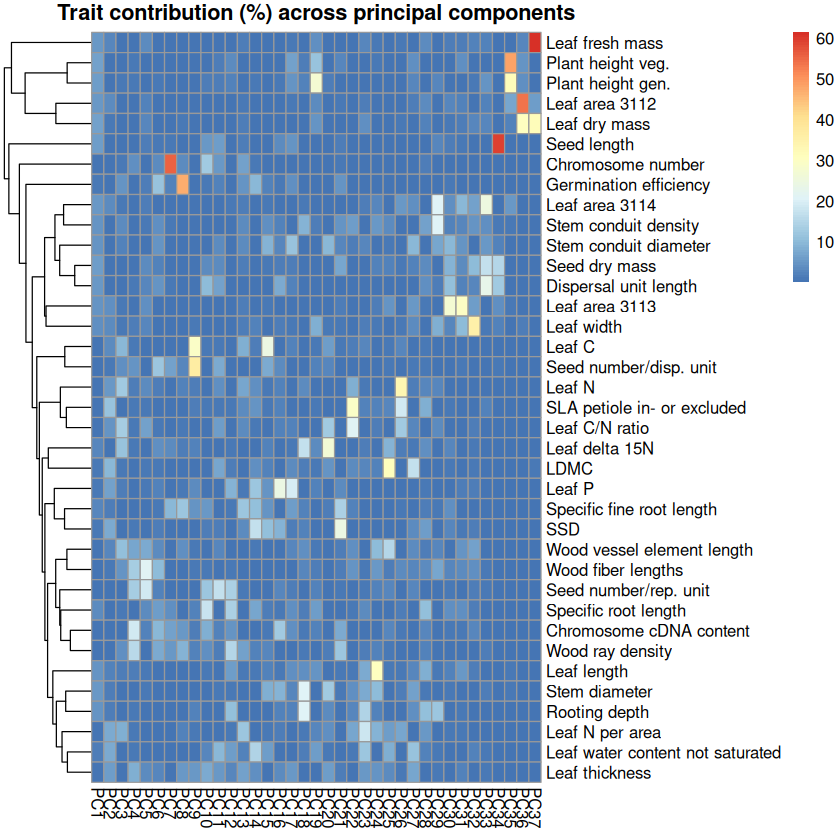

In [43]:
library(pheatmap)

pheatmap(contrib,
         cluster_rows = TRUE,
         cluster_cols = FALSE,
         scale = "none",
         display_numbers = FALSE,
         main = "Trait contribution (%) across principal components")


pdf 
  2

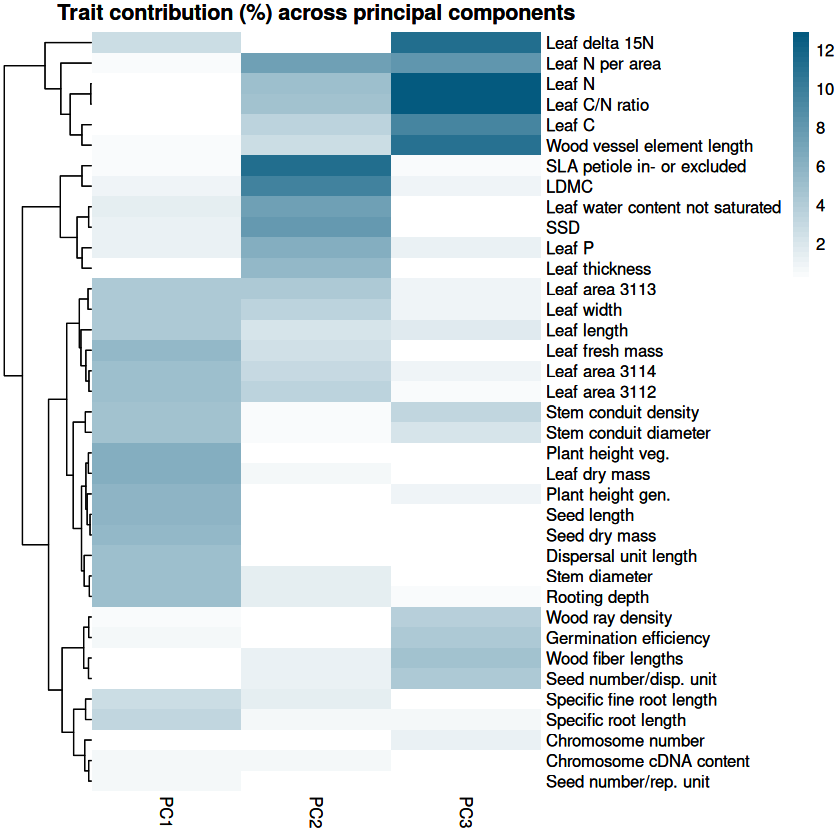

In [44]:
final_plot <- pheatmap(contrib[, 1:3],
         cluster_rows = TRUE,
         cluster_cols = FALSE,
         scale = "none",
         display_numbers = FALSE,
         main = "Trait contribution (%) across principal components",
         color = colorRampPalette(c("#FFFFFF", "#045A7FFF"))(50),
         border_color = NA)

png(file = "~/Func_Neo_Phytes/Results/Figures/trait_contribution_heatmap_no_border_1-3_misstree.png", width = 6, height = 7, units = "in", res = 300)

print(final_plot)
dev.off()

print(final_plot)


pdf 
  2

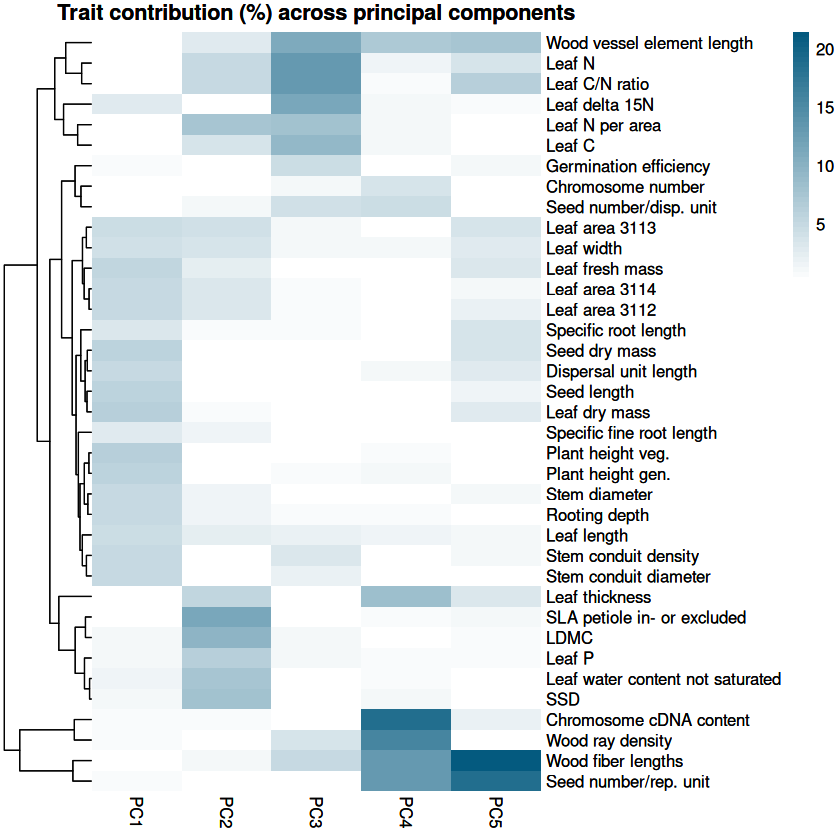

In [45]:
final_plot <- pheatmap(contrib[, 1:5],
         cluster_rows = TRUE,
         cluster_cols = FALSE,
         scale = "none",
         display_numbers = FALSE,
         main = "Trait contribution (%) across principal components",
         color = colorRampPalette(c("#FFFFFF", "#045A7FFF"))(50),
         border_color = NA)

png(file = "~/Func_Neo_Phytes/Results/Figures/trait_contribution_heatmap_no_border_1-5_misstree.png", width = 6, height = 7, units = "in", res = 300)

print(final_plot)
dev.off()

print(final_plot)


In [46]:
# filter contrib for PC1, PC2, PC3 with values greater than 5
contrib_filtered <- contrib[apply(contrib[, 1:3], 1, function(x) any(x > 5)), 1:3]  

pdf 
  2

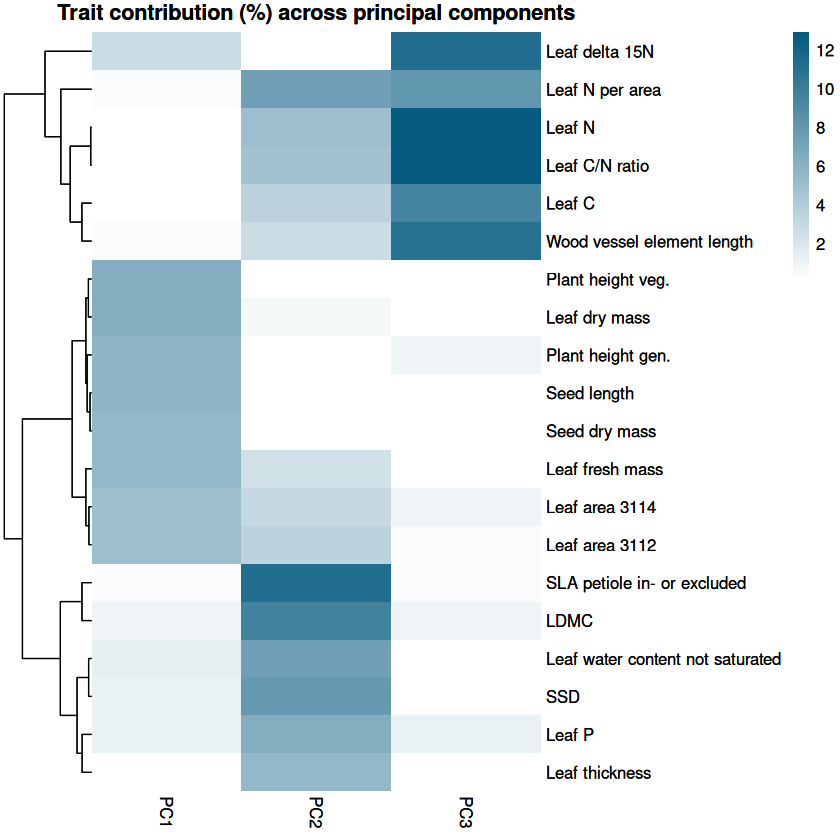

In [47]:
final_plot <- pheatmap(contrib_filtered[, 1:3],
         cluster_rows = TRUE,
         cluster_cols = FALSE,
         scale = "none",
         display_numbers = FALSE,
         main = "Trait contribution (%) across principal components",
         color = colorRampPalette(c("#FFFFFF", "#045A7FFF"))(50),
         border_color = NA)

png(file = "~/Func_Neo_Phytes/Results/Figures/trait_contribution_heatmap_masked_1-3_filtered_misstree.png", width = 6, height = 7, units = "in", res = 300)

print(final_plot)
dev.off()

print(final_plot)


In [48]:
contrib_filtered

,PC1,PC2,PC3
SLA petiole in- or excluded,0.3766243385,1.115917e+01,0.42656768
Leaf N,0.0002425063,4.978397e+00,12.87413085
Leaf N per area,0.3106486143,7.430925e+00,8.06056701
Leaf C/N ratio,0.0135769077,4.812162e+00,12.90037683
Leaf water content not saturated,1.3880611464,7.464225e+00,0.01897460
Leaf C,0.0811074502,3.431221e+00,9.32901916
Leaf P,1.0959041610,6.373898e+00,1.26023218
Leaf area 3114,5.0735620268,3.080653e+00,0.85352141
Leaf area 3112,5.1244891766,3.408698e+00,0.48817771
Plant height veg.,6.3094061811,1.869582e-01,0.24325345


In [49]:
trait_pca <- as.data.frame(pca_result$rotation)
trait_pca$trait <- rownames(trait_pca)
rownames(trait_pca) <- NULL


In [50]:
# save trait_pca to file
fwrite(trait_pca, "/net/scratch/swolf/GBIF/trait_pca_glonaf_wcvp_res3_try6_mean_imp_CS_log10_notrim_misstree.csv")

### Variance explained by each axis


[1] 0.62051


pdf 
  2

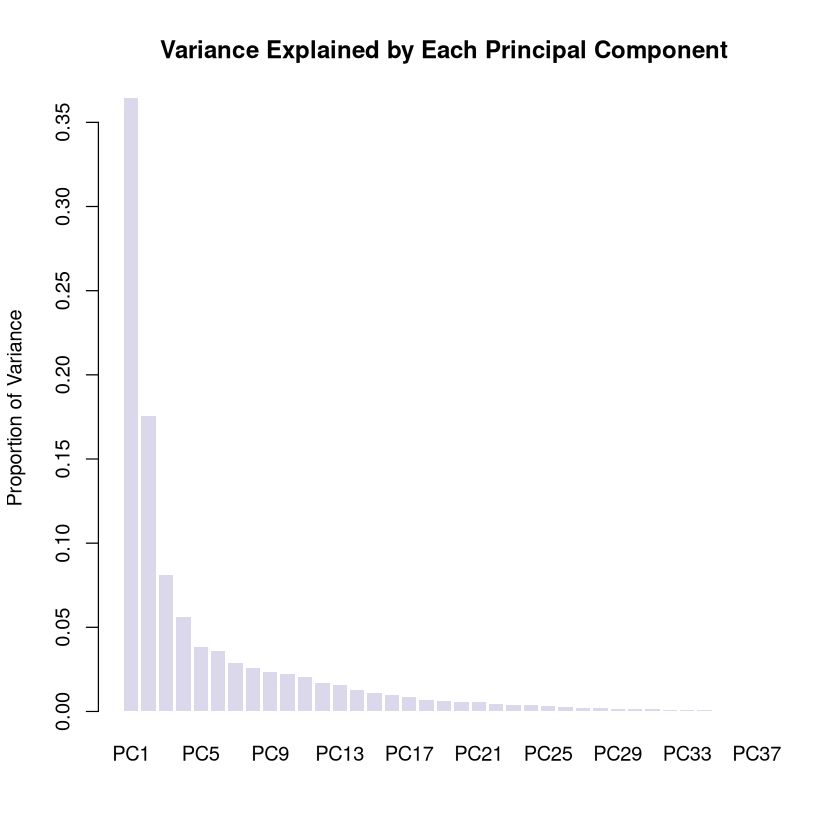

In [51]:

# Variance explained by each PC
explained_variance <- summary(pca_result)$importance[2,]

# sum of variance explained by first 3 PCs
print(sum(explained_variance[1:3]))

pdf(
  #file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_global_var_explained.pdf"), 
  file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_global_var_explained_GBIF_wcvp_CS_log10_misstree.pdf"), 
  #file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_global_var_explained_GBIF_wcvp_CS_n100.pdf"), 
  width = 10,  # Width in inches
  height = 7   # Height in inches
)
barplot(explained_variance, main = "Variance Explained by Each Principal Component", 
        col = "#dad8eaff", ylab = "Proportion of Variance", border = NA)

dev.off()

# Print the barplot to the screen
barplot(explained_variance, main = "Variance Explained by Each Principal Component", 
        col = "#dad8eaff", ylab = "Proportion of Variance", border = NA)



pdf 
  2

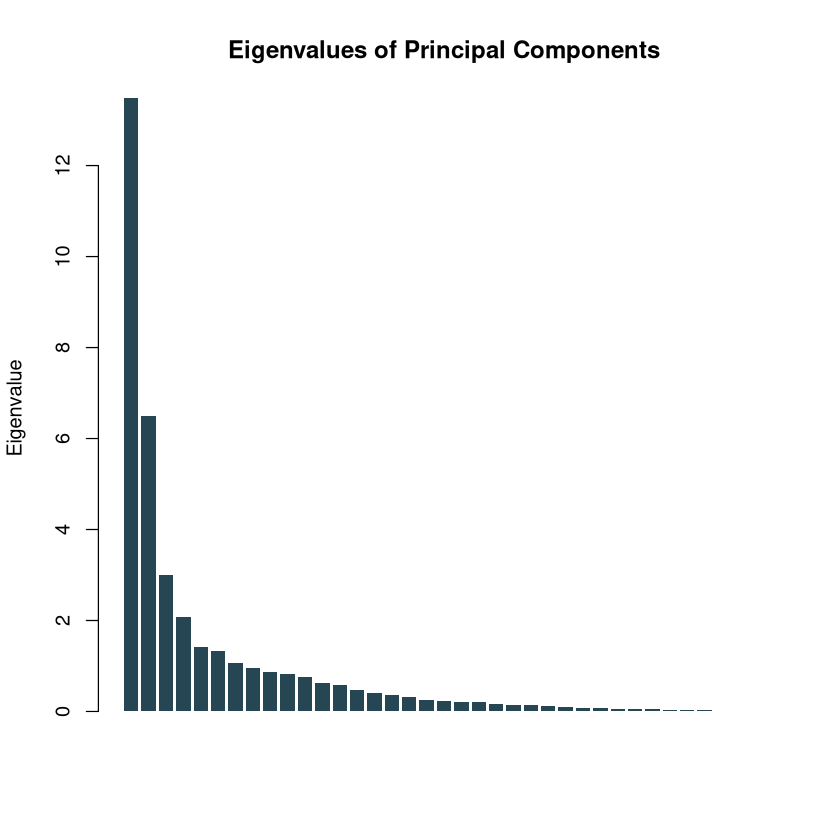

In [52]:
# plot the eigenvalues
eigenvalues <- pca_result$sdev^2
pdf(
  file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_global_eigenvalues_wcvp_CS_log10_notrim_misstree.pdf"), 
  #file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_global_eigenvalues_wcvp_CS_n100.pdf"), 

  width = 10,  # Width in inches
  height = 7   # Height in inches
)       
barplot(eigenvalues, main = "Eigenvalues of Principal Components", 
        col = "#264653", ylab = "Eigenvalue", border = NA)  

dev.off()
barplot(eigenvalues, main = "Eigenvalues of Principal Components", 
        col = "#264653", ylab = "Eigenvalue", border = NA)  



In [53]:
explained_variance

PC1     PC2     PC3     PC4     PC5     PC6     PC7     PC8     PC9    PC10 
0.36424 0.17545 0.08082 0.05613 0.03818 0.03597 0.02893 0.02553 0.02357 0.02254 
   PC11    PC12    PC13    PC14    PC15    PC16    PC17    PC18    PC19    PC20 
0.02042 0.01686 0.01579 0.01275 0.01079 0.00964 0.00830 0.00664 0.00601 0.00584 
   PC21    PC22    PC23    PC24    PC25    PC26    PC27    PC28    PC29    PC30 
0.00554 0.00449 0.00407 0.00401 0.00299 0.00237 0.00204 0.00195 0.00158 0.00151 
   PC31    PC32    PC33    PC34    PC35    PC36    PC37 
0.00118 0.00110 0.00105 0.00077 0.00040 0.00035 0.00020

### Format and save result

In [54]:
library(data.table)

# Flip PC1
pca_scores <- data.table(
  h3_res3 = gbif_imputed$h3_res3,
  group = gbif_imputed$group,  # "all" or "native"
  PC1 = pca_result$x[, 1],  # flip the sign of PC1 for GBIF_glonaf, GBIF_glonaf_wcvp_woody, GBIF_glonaf_wcvp_nonwoody
  PC2 = pca_result$x[, 2],   # flip the sign of PC2 for GBIF_glonaf_wcvp_all
  PC3 = pca_result$x[, 3],
  PC4 = pca_result$x[, 4],
  PC5 = pca_result$x[, 5]
)
head(pca_scores)

h3_res3,group,PC1,PC2,PC3,PC4,PC5
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83001afffffffff,all,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100
83001afffffffff,native,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100
83001cfffffffff,all,-10.005360,-0.2380058,0.2491376,2.9137390,0.9757523
83001cfffffffff,native,-9.988809,-0.3014320,0.2822225,2.9136399,0.9666302
83001efffffffff,all,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540
83001efffffffff,native,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540


In [55]:
# Reshape from long to wide format
pca_scores_wide <- dcast(pca_scores, h3_res3 ~ group, value.var = c("PC1", "PC2", "PC3", "PC4", "PC5"))
head(pca_scores_wide)

h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC5_all,PC5_native
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83001afffffffff,-10.334354,-10.334354,1.3228614,1.3228614,-1.7255834,-1.7255834,1.0414618,1.0414618,2.1589100,2.1589100
83001cfffffffff,-10.005360,-9.988809,-0.2380058,-0.3014320,0.2491376,0.2822225,2.9137390,2.9136399,0.9757523,0.9666302
83001efffffffff,-10.690103,-10.690103,-0.8713593,-0.8713593,-0.9452468,-0.9452468,-0.2685651,-0.2685651,1.3119540,1.3119540
830025fffffffff,-9.944177,-9.944177,0.6878973,0.6878973,-1.3408168,-1.3408168,-0.1235437,-0.1235437,2.0710218,2.0710218
830028fffffffff,-10.170143,-10.170143,-1.6934754,-1.6934754,-1.1072216,-1.1072216,0.0874861,0.0874861,0.7784430,0.7784430
830029fffffffff,-9.799682,-9.799682,-0.7173000,-0.7173000,-1.1438049,-1.1438049,1.0295538,1.0295538,0.8704674,0.8704674


In [56]:
# Step 2: Join the pca_scores with gbif_down by 'gbifID'
gbif_summary <- pca_scores_wide[gbif_summary, on = "h3_res3"]
head(gbif_summary)

h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC5_all,⋯,X.X47..mean_native,X.X47..median_all,X.X47..median_native,X.X47..percent_change_mean,X.X47..percent_change_median,X.X47..n_na_all,X.X47..perc_na_all,X.X47..n_na_native,X.X47..perc_na_native,resolution
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<int>,<dbl>,<chr>
83831efffffffff,4.791148,3.7766291,0.9721051,1.1088903,-0.5431612,-0.34431243,-0.42136533,1.02068041,0.5774828,⋯,0.322,0.352,0.354,0.00,-0.56,37,24.67,16,19.05,h3_res3
838218fffffffff,3.901431,5.0583305,1.1307036,0.5138983,-0.2462778,0.05720839,-0.47252956,-0.54789381,0.2955384,⋯,0.293,0.276,0.285,-6.83,-3.16,10,26.32,10,34.48,h3_res3
838233fffffffff,5.296893,7.9646210,0.7344789,0.1759947,-0.3730047,0.69734595,-1.40549703,-1.56500099,1.3152798,⋯,0.290,0.324,0.280,3.79,15.71,8,26.67,7,43.75,h3_res3
838230fffffffff,5.160745,6.4376781,1.1521587,0.7619902,-0.9373319,-0.01892562,0.09261112,0.81461843,0.8814747,⋯,0.308,0.305,0.315,-1.30,-3.17,11,31.43,8,40.00,h3_res3
83be4dfffffffff,0.601728,0.6843753,-7.7335394,-7.9253400,2.7755032,2.86621941,0.47608132,0.46676308,-0.6878360,⋯,0.496,0.497,0.514,-1.21,-3.31,7924,25.99,7837,26.22,h3_res3
835f12fffffffff,3.826443,4.0358059,0.6390104,0.5204550,0.7138565,0.88520839,0.10669870,0.06196723,0.1184253,⋯,0.303,0.305,0.307,-0.33,-0.65,2374,21.61,2095,22.12,h3_res3


In [57]:
fwrite(gbif_summary, "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree.csv", row.names = F, quote = T)


In [58]:
# Join the pca_scores with gbif by hexagon id
gbif_summary2 <- pca_scores[gbif_imputed, on = c("h3_res3", "group")]
head(gbif_summary2)

h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,⋯,X.X237,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83001afffffffff,all,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,-0.016,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152
83001afffffffff,native,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,-0.016,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152
83001cfffffffff,all,-10.005360,-0.2380058,0.2491376,2.9137390,0.9757523,1,1,16.22,⋯,-0.119,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3166111,0.175
83001cfffffffff,native,-9.988809,-0.3014320,0.2822225,2.9136399,0.9666302,1,1,16.22,⋯,-0.119,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3291221,0.175
83001efffffffff,all,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,0.122,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211
83001efffffffff,native,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,0.122,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211


In [59]:
fwrite(gbif_summary2, "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree_group.csv", row.names = F, quote = T) 



## Plot global PCA

I added PCA for wcvp version already in summary_stats.ipynb

In [60]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

gbif_summary <- fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree.csv")
head(gbif_summary)

h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC5_all,⋯,X.X47..mean_native,X.X47..median_all,X.X47..median_native,X.X47..percent_change_mean,X.X47..percent_change_median,X.X47..n_na_all,X.X47..perc_na_all,X.X47..n_na_native,X.X47..perc_na_native,resolution
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<int>,<dbl>,<chr>
83831efffffffff,4.791148,3.7766291,0.9721051,1.1088903,-0.5431612,-0.34431243,-0.42136533,1.02068041,0.5774828,⋯,0.322,0.352,0.354,0.00,-0.56,37,24.67,16,19.05,h3_res3
838218fffffffff,3.901431,5.0583305,1.1307036,0.5138983,-0.2462778,0.05720839,-0.47252956,-0.54789381,0.2955384,⋯,0.293,0.276,0.285,-6.83,-3.16,10,26.32,10,34.48,h3_res3
838233fffffffff,5.296893,7.9646210,0.7344789,0.1759947,-0.3730047,0.69734595,-1.40549703,-1.56500099,1.3152798,⋯,0.290,0.324,0.280,3.79,15.71,8,26.67,7,43.75,h3_res3
838230fffffffff,5.160745,6.4376781,1.1521587,0.7619902,-0.9373319,-0.01892562,0.09261112,0.81461843,0.8814747,⋯,0.308,0.305,0.315,-1.30,-3.17,11,31.43,8,40.00,h3_res3
83be4dfffffffff,0.601728,0.6843753,-7.7335394,-7.9253400,2.7755032,2.86621941,0.47608132,0.46676308,-0.6878360,⋯,0.496,0.497,0.514,-1.21,-3.31,7924,25.99,7837,26.22,h3_res3
835f12fffffffff,3.826443,4.0358059,0.6390104,0.5204550,0.7138565,0.88520839,0.10669870,0.06196723,0.1184253,⋯,0.303,0.305,0.307,-0.33,-0.65,2374,21.61,2095,22.12,h3_res3


In [61]:
library(cowplot)

make_pca_biplot <- function(pca_result,
                            gbif_imputed,
                            pcs = c(1, 2),
                            show_loading_labels = TRUE,
                            arrow_scale = 10,
                            label_offset = 0.3) {
  
  # -----------------------------
  # Extract PCA scores
  # -----------------------------
  
  pca_scores <- as.data.frame(pca_result$x[, pcs])
  names(pca_scores) <- c("PCx", "PCy")
  pca_scores$group <- gbif_imputed$group

  # Actual PC names
  pc_x_name <- paste0("PC", pcs[1])
  pc_y_name <- paste0("PC", pcs[2])
  
  # -----------------------------
  # Extract loadings
  # -----------------------------
  
  loadings <- as.data.frame(pca_result$rotation[, pcs])
  names(loadings) <- c("PCx", "PCy")
  loadings$trait <- rownames(loadings)
  
  # Scale loading arrows
  loadings <- loadings %>%
    mutate(
      PCx = PCx * arrow_scale,
      PCy = PCy * arrow_scale,
      arrow_length = sqrt(PCx^2 + PCy^2),
      unit_x = PCx / arrow_length,
      unit_y = PCy / arrow_length,
      label_x = PCx + label_offset * unit_x,
      label_y = PCy + label_offset * unit_y
    )
  
  # Extract numbers from trait names
  loadings$trait <- stringr::str_extract(loadings$trait, "\\d+")
  
  # -----------------------------
  # Base PCA plot
  # -----------------------------
  
  p <- ggplot(pca_scores, aes(x = PCx, y = PCy)) +
  labs(
    x = pc_x_name,
    y = pc_y_name
  ) +
    
    stat_density_2d(
      geom = "polygon",
      aes(
        alpha = ..level..,
        fill = group,
        group = group
      ),
      bins = 10
    ) +

    scale_alpha_continuous(
    range = c(0.03, 0.4),
    guide = "none"
    ) +
    
    scale_fill_manual(
      values = c(
        "all" = "#fc8d62",
        "native" = "#2ed5c9"
      )
    ) +
    
    theme_minimal() +
    
    theme(
      panel.grid = element_blank(),
      legend.position = "right",
      axis.title = element_text(size = 14),
      axis.text = element_text(size = 14),
      panel.border = element_rect(
        color = "darkgrey",
        fill = NA,
        linewidth = 1
      )
    ) +
    
    # Loading arrows
    geom_segment(
      data = loadings,
      aes(
        x = 0,
        y = 0,
        xend = PCx,
        yend = PCy
      ),
      arrow = arrow(length = unit(0.1, "cm")),
      color = "#045A7FFF",
      linewidth = 0.5
    )
  
  # -----------------------------
  # Optional loading labels
  # -----------------------------
  
  if (show_loading_labels) {
    
    p <- p +
      geom_text(
        data = loadings,
        aes(
          x = label_x,
          y = label_y,
          label = trait
        ),
        color = "#2F86AC",
        size = 4,
        hjust = 0.5,
        vjust = 0.5
      )
  }
  
  # -----------------------------
  # Zero lines
  # -----------------------------
  
  p <- p +
    geom_hline(
      yintercept = 0,
      color = "dimgrey",
      linetype = "dashed"
    ) +
    geom_vline(
      xintercept = 0,
      color = "dimgrey",
      linetype = "dashed"
    )
  
  # -----------------------------
  # Marginal density: PCx
  # -----------------------------
  
  xdens <- axis_canvas(p, axis = "x") +
    
    geom_density(
      data = pca_scores,
      aes(x = PCx, fill = group),
      alpha = 0.3,
      linewidth = 0.5,
      adjust = 1.5,
      color = NA
    ) +
    
    scale_fill_manual(
      values = c(
        "all" = "#fc8d62",
        "native" = "#2ed5c9"
      )
    ) +
    
    geom_vline(
      data = pca_scores %>%
        group_by(group) %>%
        summarise(median_PCx = median(PCx, na.rm = TRUE)),
      aes(
        xintercept = median_PCx,
        color = group
      ),
      linetype = "solid",
      linewidth = 1
    ) +
    
    scale_color_manual(
      values = c(
        "all" = "#fc8d62",
        "native" = "#2ed5c9"
      )
    )
  
  # -----------------------------
  # Marginal density: PCy
  # -----------------------------
  
  ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) +
    
    geom_density(
      data = pca_scores,
      aes(x = PCy, fill = group),
      alpha = 0.3,
      linewidth = 0.5,
      adjust = 1.5,
      color = NA
    ) +
    
    scale_fill_manual(
      values = c(
        "all" = "#fc8d62",
        "native" = "#2ed5c9"
      )
    ) +
    
    geom_vline(
      data = pca_scores %>%
        group_by(group) %>%
        summarise(median_PCy = median(PCy, na.rm = TRUE)),
      aes(
        xintercept = median_PCy,
        color = group
      ),
      linetype = "solid",
      linewidth = 1
    ) +
    
    scale_color_manual(
      values = c(
        "all" = "#fc8d62",
        "native" = "#2ed5c9"
      )
    ) +
    
    coord_flip()
  
  # -----------------------------
  # Combine plot + marginal densities
  # -----------------------------
  
  final_plot <- p %>%
    insert_xaxis_grob(
      xdens,
      grid::unit(1, "in"),
      position = "top"
    ) %>%
    insert_yaxis_grob(
      ydens,
      grid::unit(1, "in"),
      position = "right"
    ) %>%
    ggdraw()
  
  return(final_plot)
}

Warning message:
“The dot-dot notation (`..level..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(level)` instead.”
Warning message:
“Removed 604 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 777 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 604 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 777 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 480 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 963 rows containing non-finite outside the scale range
(`stat_density()`).”


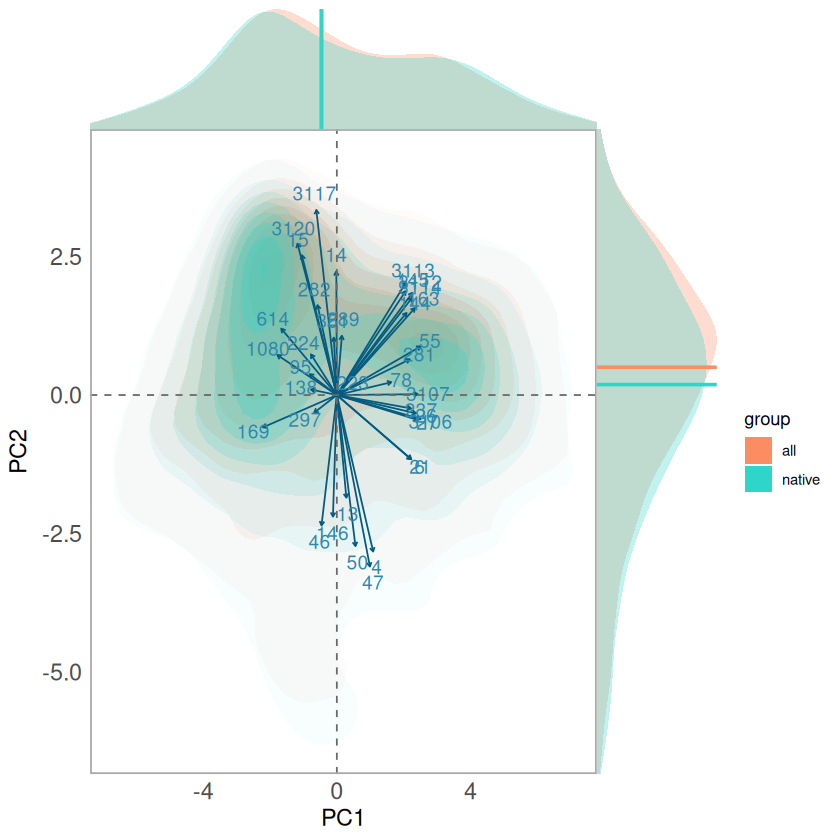

Warning message:
“Removed 614 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 963 rows containing non-finite outside the scale range
(`stat_density()`).”


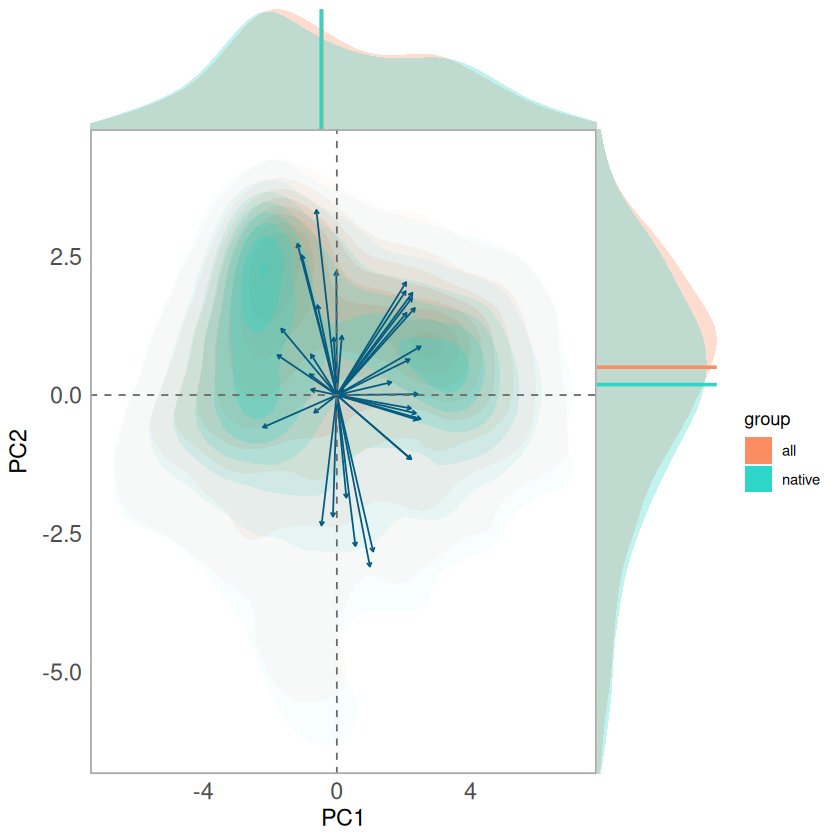

Warning message:
“Removed 1990 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 495 rows containing non-finite outside the scale range
(`stat_density()`).”


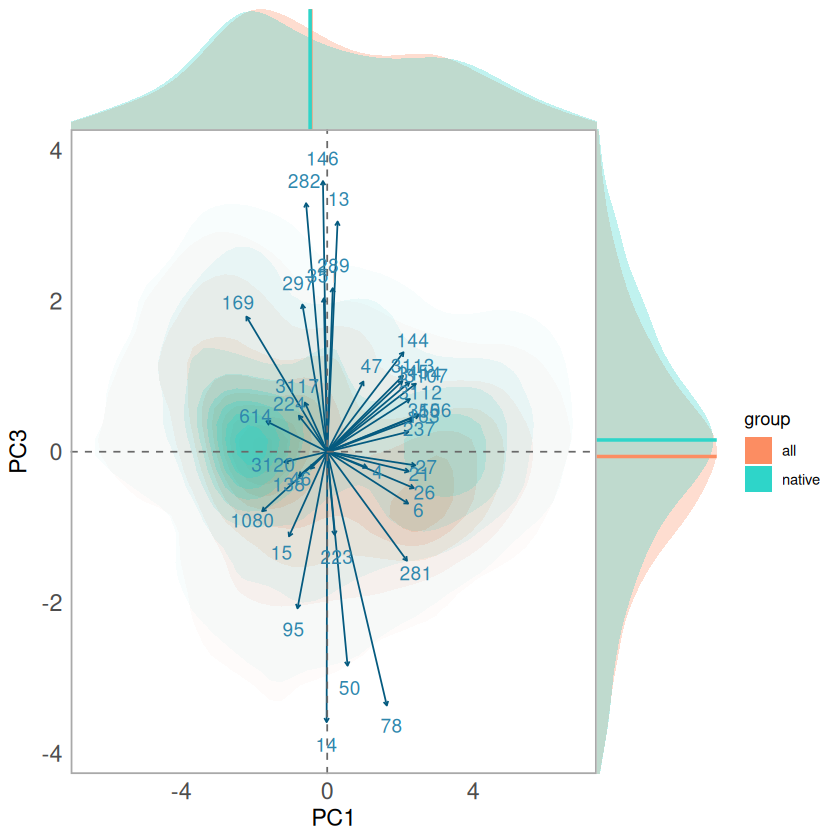

Warning message:
“Removed 2257 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 595 rows containing non-finite outside the scale range
(`stat_density()`).”


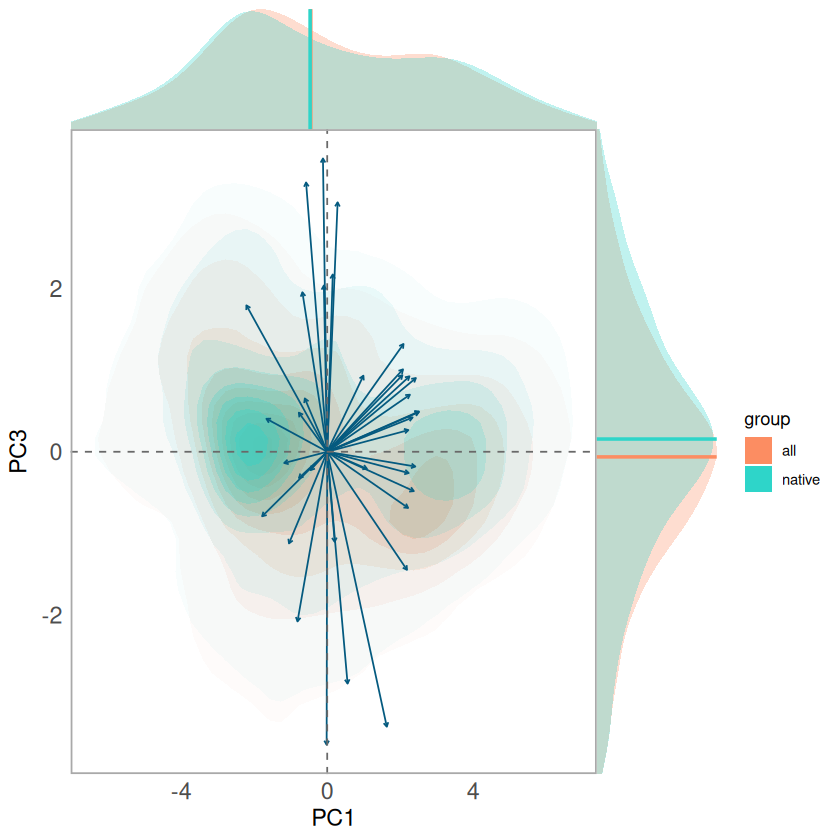

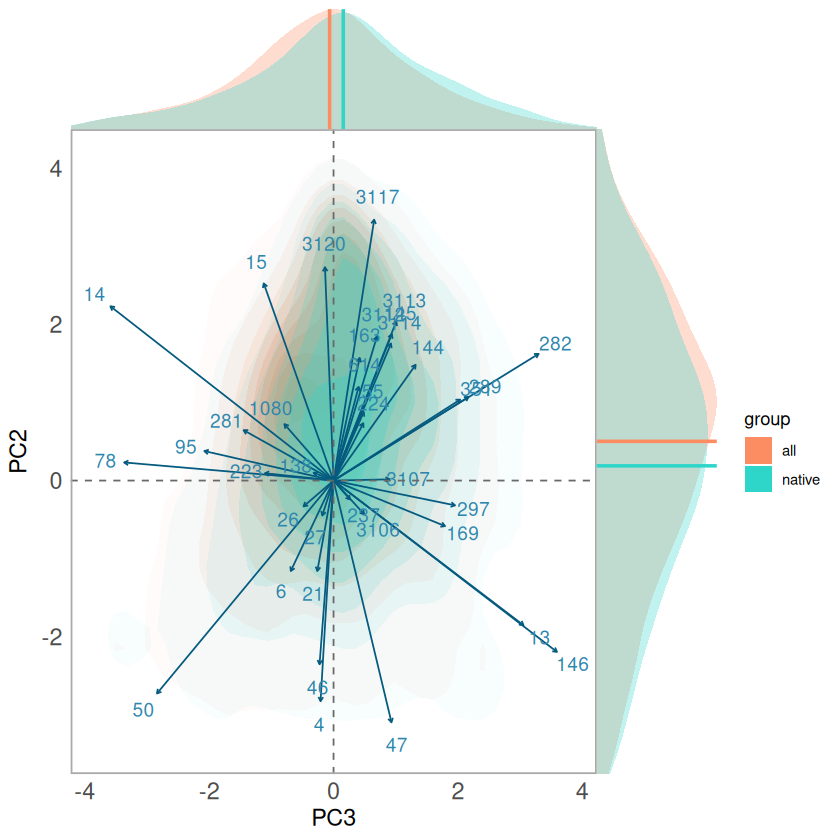

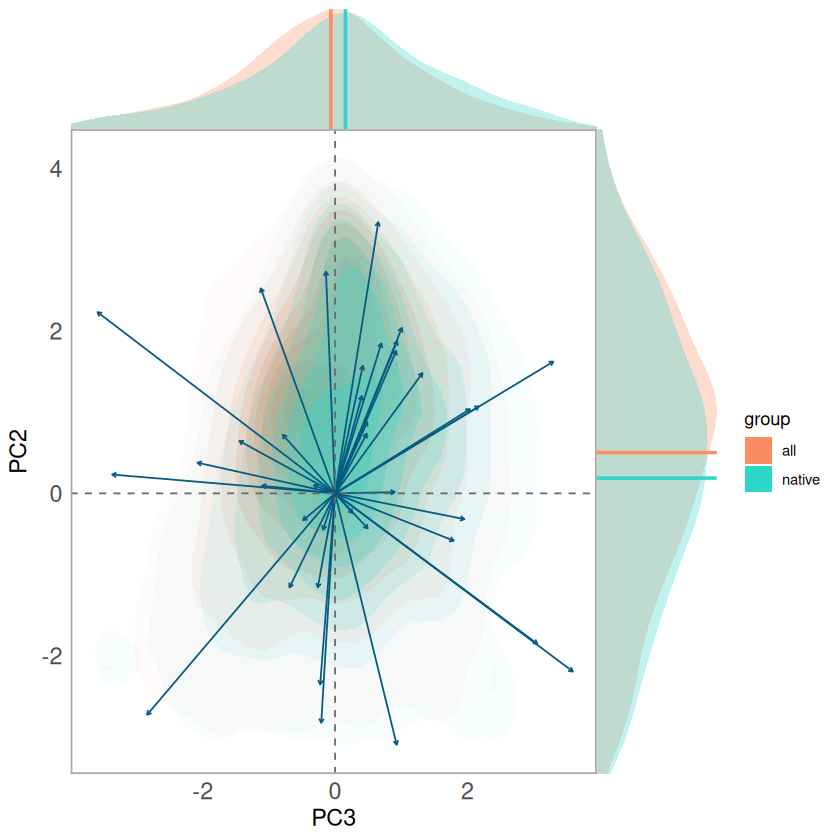

In [62]:
pc_combinations <- list(
  c(1, 2),
  c(1, 3),
  c(3, 2)
)

label_options <- c(TRUE, FALSE)

for (pcs in pc_combinations) {
  
  for (show_labels in label_options) {
    
    final_plot <- make_pca_biplot(
      pca_result,
      gbif_imputed,
      pcs = pcs,
      show_loading_labels = show_labels
    )
    
    # Create filename
    pc_name <- paste0("PC", pcs[1], "_PC", pcs[2])
    label_name <- ifelse(show_labels, "labels", "nolabels")
    
    filename <- paste0(
      "~/Func_Neo_Phytes/Results/Figures/",
      "pca_global_densities_biplot_GBIF_wcvp_all_CS_log10_notrim_misstree_",
      pc_name, "_", label_name, ".png"
    )
    
    # Save
    png(
      file = filename,
      width = 9,
      height = 7,
      units = "in",
      res = 300
    )
    
    print(final_plot)
    dev.off()
    
    # Print to screen
    print(final_plot)
  }
}